# Vectorial Word Representations

## Background
Representing words as dense vectors over a finite-dimensional space was one of the recent breakthroughs in Natural Language Processing. Vectorial representations allow space-efficient, informationally rich storage of words that adequately captures their semantic content and enables numerical computation on them. Word vectors are the standard input representation for machine learning architectures for language processing. Even though new methods for constructing such representations emerge frequently, the original set of published papers remain a de facto point of reference as well as a good starting point. For this assignment, you will be asked to implement a small-scale variant of one such paper, namely [Global Word Vectors for Word Representation](https://nlp.stanford.edu/pubs/glove.pdf) ("the GloVe paper").

Notes on the paper will appear throughout the notebook to guide you along the code. It is, however, important to read and understand the paper, its terminology and the theory behind it before attempting to go through with the assignment. Some of the tasks will also require addressing the paper directly.

---

There are 2 types of tasks in this assignment:
- coding tasks --- asking you to write code following specifications provided; Most of the tasks come with test cases for sanity-check. Still, if something is not clear, <ins>do ask questions to lab teachers</ins>. When working with tensors, you have to use tensor-related operations instead of, e.g., inefficiently looping through tensor rows and columns.
- interpretation questions --- asking you to interpret the data or the results of the model

Each comes with its predefined points (totaling to 50pt). Some coding tasks have 0 points but solving them will be useful for you.

---

You are greatly encouraged to add comments to your code describing what particular lines of code do (in general, a great habit to have in your coding life).
Additionally please follow these rules when submitting the notebook:

* Put all code in the cell with the `# YOUR CODE HERE` comment.
* Use torch operators when processing tensors (e.g., don't iterate over tensor elements)
* For theoretical questions, put your solution in the `YOUR ANSWER HERE` cell and keep the header(!).
* Don't change or delete any initially provided cells, either text or code, unless explicitly instructed to do so.
* Don't delete the comment lines `# TEST...` or edit their code cells. The test cells are for sanity checking. Passing them doesn't necessarily means that your code is fine.
* Don't change the names of provided functions and variables or arguments of the functions.
* Don't clear the output of your code cells.
* Don't output unnecessary info (e.g., printing variables for debugging purposes). This clutters the notebook and slows down the grading. You can have print() in the code, but comment them out before submitting the notebook.
* Delete those cells that you inserted for your own debuging/testing purposes.
* Don't forget to fill in the contribution information.
* Test your code and **make sure we can run your notebook** in the colab environment.
* A single notebook file (without archiving) per group should be submitted via BB.

<font color="red">You following these rules helps us to grade the submissions relatively efficiently. If these rules are violated, a submission will be subject to penalty points.</font>


# <font color="red">Contributions</font>
Marieke Morganwiese 

Chuangqi Li



#TODO: Update later if we change it
# <font color="red">Task Distribution</font>
Marieke Morganwiese:

Stage 1: Corpus Statistics -  Tasks: c1.1, c1.2, c1.3

Stage 2: Probing Words - Tasks: c2.1, c2.2, i1, i2

Stage 3: GloVe Model Implementation (Dense Vectors) - Tasks: c3, c4, c5



Chuangqi Li: 

Stage 4: Model Training: Tasks - c6.1, c6.2

Stage 5: Model Validation: Tasks - i3, c7, i4, c8, i5


Marieke Morganwiese and Chuangqi Li: 

Stage 6: Challenge-Based Assignment Tasks -c9, i6

In [68]:
#imports
#TODO: remove this entire cell later before handing in
%pip install torch

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 23.2.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


## Corpus Statistics

The paper's proposed model, GloVe, aims to densely represent words in a way that captures the global corpus statistics.

The construction it encodes is the word __co-occurrence matrix__. A co-occurrence matrix is a simplistic data structure that counts the number of times each word has appeared within the context of every other word. The definition of a context varies; usually, context is implied to be a fixed-length span (that may or may not be allowed to escape sentence boundaries) around a word.

For instance, in the sentence below and for a context length of 2, the word <span style="color:pink">__Earth__</span> occurs in the context of <span style="color:lightgreen">made</span> (1), <span style="color:lightgreen">on</span> (1), <span style="color:lightgreen">as</span> (1), <span style="color:lightgreen">an</span> (1).

> "He struck most of the friends he had <span style="color:lightgreen">made on</span> <span style="color:pink">__Earth__</span> <span style="color:lightgreen">as an</span> eccentric"

Similarly, the word <span style="color:pink">__friends__</span> occurs in the context of <span style="color:lightgreen">of</span> (1), <span style="color:lightgreen">the</span> (1), <span style="color:lightgreen">he</span> (1), <span style="color:lightgreen">had</span> (1).

> "He struck most <span style="color:lightgreen">of the</span> <span style="color:pink">__friends__</span> <span style="color:lightgreen">he had</span> made on Earth as an eccentric"

An alternative definition of a context would be, for instance, the variable-length windows spanned by a full sentence.

Contexts may be summed across sentences or entire corpora; the summed context of <span style="color:pink">__he__</span> in the example sentence is: <span style="color:lightgreen">struck</span> (1), <span style="color:lightgreen">most</span> (1), <span style="color:lightgreen">the</span> (1), <span style="color:lightgreen">friends</span> (1), <span style="color:lightgreen">had</span> (1), <span style="color:lightgreen">made</span> (1).



In [69]:
import pickle, math
import torch

from torch import FloatTensor, LongTensor
from typing import Dict, Callable, List
# torch.set_printoptions(precision=8) #to increase precision of printing floats

In [70]:
# this command downloads the pickle file.
# This is not a python code, it is a unix code. You can run system commands in jupyter notebooks.
#TODO: uncomment the 2 lines below before handing in the file.
# !wget -nv -O HP-Counts-24.zip https://naturallogic.pro/_files_/download/MLHVL/HP-Counts-24.zip
# !unzip -o HP-Counts-24.zip

#TODO: ask teacher if its ok to replace the above code with this, because it seems that the above code is made for linux and I am running it on windows:
import urllib.request
import zipfile

url = "https://naturallogic.pro/_files_/download/MLHVL/HP-Counts-24.zip"
zip_path = "HP-Counts-24.zip"

urllib.request.urlretrieve(url, zip_path)

with zipfile.ZipFile(zip_path, "r") as zip_ref:
    zip_ref.extractall(".")

print("Downloaded and extracted successfully!")

Downloaded and extracted successfully!


In [71]:
with open("HP-Counts.p", "rb") as f:
    vocab, contexts, X = pickle.load(f)

Let's inspect the top 10 most frequent words in the context of the word 'portrait'.

In [72]:
sorted([(item, value) for item, value in contexts["portrait"].items()], key=lambda x: x[1], reverse=True)[:10]

[('harry', 124),
 ('said', 114),
 ('hole', 85),
 ('ron', 57),
 ('hermione', 54),
 ('room', 48),
 ('fat', 45),
 ('lady', 43),
 ('common', 37),
 ('back', 31)]

The co-occurrence matrix of a very large corpus should give a meaningful summary of how a word is used in general. A single row of that matrix is already a __word vector__ of size $N$. However such vectors are extremely sparse, and for large corpora the size of $N$ will become unwieldy. We will follow the paper in designing an algorithm that can compress the word vectors while retaining most of their informational content.

<div class="alert alert-block alert-info">
<b>Note:</b>
For the resulting vectors to actually be informative, the source corpus should have a size of at least a few billion words; on the contrary, our corpus enumerates merely a million words, so we can't expect our results to be as great.
</div>

### From co-occurrence to probabilities

Our matrix $X$ is very sparse; most of its elements are zero.

Find what the ratio of non-zero elements is.  
Check if the matrix is symmetric (think about why it should (not) be).

_Hint_: The function `non_zero_ratio` should return a `float` rather than a `FloatTensor`. Remember `.item()`.

In [73]:
# @title c1.1 [0pt]
def non_zero_ratio(sparse_matrix: LongTensor) -> float:
    #count it using numel() which returns the total number of elements
    count_total = sparse_matrix.numel()

    #count non-zero matrix, returns a matrix filled with 'true' and 'false'
    non_zero_matrix = (sparse_matrix != 0)
    #use sum to count the 'true' in the matrix, and .item() to convert the tensor to a number
    count_non_zero = non_zero_matrix.sum().item()

    ratio = count_non_zero / count_total

    #compare
    #TODO: remove the print statements before handing in the file
    print(f"Total count: {count_total}, Non-zero count: {count_non_zero}")
    print(f"Non-zero ratio: {ratio}")

    return ratio



In [74]:
# TEST c1.1
assert 0.1 < non_zero_ratio(X) < 0.2

Total count: 18472804, Non-zero count: 3442735
Non-zero ratio: 0.1863677544567679


We will soon need to perform division and find the logarithm of ${X}$. Neither of the two operations are well-defined for $0$. That's why for further processing we want to have a matrix without any zero elements.

Change the matrix's datatype to a `torch.float` and add a small constant to it such as $0.1$ to ensure numerical stability while maintaining sparsity. The obtained matrix will be used in the remaining sections (not the original one).

In [75]:
# @title c1.2 [0pt]
X1 = X.float() + 0.1

In [76]:
# TEST c1.2
# sanity-check: should return 1.0, and it does.
assert non_zero_ratio(X1) == 1

Total count: 18472804, Non-zero count: 18472804
Non-zero ratio: 1.0


In [77]:
# This finds the co-occurance of 'harry' and 'harry' 
X1[vocab['harry'],vocab['harry']]

tensor(11504.0996)

From the paper:
> Let the matrix of word-word co-occurrence counts be denoted by $X$, whose entries $X_{ij}$ tabulate the number of times word $j$ occurs in the context of word $i$.  Let $X_i$= $\sum_{k} X_{ik}$ be the number of times any word appears in the context of word $i$. Finally, let $P_{ij} = P(j  | i) =  X_{ij}/X_i$ be the probability that word $j$ appears in the context of word $i$.

Complete the function `to_probabilities` that accepts a co-occurrence matrix and returns the probability matrix $P$. Use tensor-specific functions and methods hiel doing this (e.g., don't loop through colums and rows of the tensor).

_Hint_: Remember broadcasting and `torch.sum()`.

In [78]:
# @title c1.3 [1pt]
def to_probabilities(count_matrix: FloatTensor) -> FloatTensor:
    #dim=1 means that the sum is calculated along the rows, and keepdim=True means that the output will have the same number of dimensions as the input.
    row_sums = count_matrix.sum(dim=1, keepdim=True)
    #divide each count by its row total
    probabilities = count_matrix / row_sums
    #print(probabilities[vocab['harry']])
    return probabilities

In [79]:
#new matrix P, which has probabilities of each word occuring in combination with another word
P = to_probabilities(X1) # note that we use X1 not X here

In [80]:
# TEST c1.3
assert P.shape == torch.Size([len(vocab), len(vocab)])

### Probing words

From the paper:
> Consider two words $i$ and $j$ that exhibit a particular aspect of interest. The relationship of these words can be examined by studying the ratio of their co-occurrence probabilities with various probe words, $k$.  For words $k$ related to $i$ but not $j$, we expect the ratio $P_{ik}/P_{jk}$ will be large.  Similarly, for words $k$ related to $j$ but not $i$, the ratio should be small. For words $k$ that are either related to both $i$ and $j$, or to neither, the ratio should be close to one.

Complete the function `query` that accepts two words $w_i$ and $w_j$, a vocab $V$ and a probability matrix ${P}$, maps each word to its corresponding index and returns the probability $P(j  |  i)$. If such probability is impossible to compute for input words, return float 0. probability.  

In [81]:
# @title c2.1 [1pt]
#In other words: strongly a particular word is associated with word i versus word j, by comparing the probabilities of that word appearing in each word's context.
#for example, when comparing i=harry and j=hermoine, 'smart' might be 0.2x more likely to appear in context of harry, and 'glasses' 6 times more.


# returns the value P(j|i).
# which is how often word j appears in the context of word i, divided by how often word i appears in the context of all words.
def query(word_i: str, word_j: str, vocab: Dict[str, int], prob_matrix: FloatTensor) -> float:
    #takes into account 'null' values if a word is not associated at all with i or j, and thus computations would be impossible
    if word_i not in vocab or word_j not in vocab:
        return 0.0

    #index of word i and j in the vocab dictionary
    i = vocab[word_i]
    j = vocab[word_j]

    return float(prob_matrix[i, j])

In [82]:
# TEST c2.1
assert round(query('harry', 'potter', vocab, P), 5) == 0.00353

In [83]:
round(query('harry', 'potter', vocab, P), 5)

0.00353

Then, complete the function `probe` that accepts three words $w_i$, $w_j$ and $w_k$, a vocab $V$ and a probability matrix ${P}$, calls `query` and returns the ratio $P(k |  i) / P(k  |  j)$. Let the function return 0 in case of division by 0.

In [84]:
# @title c2.2 [1pt]
#this creates a probing matrix, where the row is the word i, the column is the word j, and the value is how much more likely word k is to appear in the context of word i versus word j.
# This uses using P(k|i) / P(k|j).
def probe(word_i: str, word_j: str, word_k: str, vocab: Dict[str, int], prob_matrix: FloatTensor) -> float:
    
    p_ki = query(word_i, word_k, vocab, prob_matrix)
    p_kj = query(word_j, word_k, vocab, prob_matrix)


    if p_kj == 0: #catches a divide by zero error 
        return 0.0

    return p_ki / p_kj

In [85]:
# TEST c2.2
assert round(probe('harry', 'potter', 'stone', vocab, P), 4) == 1.3872

Let's probe a few words and examine whether the authors' claim holds even for our (tiny) corpus. **Add two pairs of your own word triplets** and experiment on them.

In [86]:
print("tea", "wand", "magic", probe("tea", "wand", "magic", vocab, P))
print("tea", "wand", "cup", probe("tea", "wand", "cup", vocab, P))
print("harry", "hermione", "smart", probe("harry", "hermione", "smart", vocab, P))
print("harry", "hermione", "said", probe("harry", "hermione", "said", vocab, P))
print( "harry", "hermione", "glasses",probe("harry", "hermione", "glasses", vocab, P))
print("harry", "hermione", "stroopwafel", probe("harry", "hermione", "Stroopwafel", vocab, P))


tea wand magic 0.018442942510795767
tea wand cup 26.14265487166853
harry hermione smart 0.918916220360532
harry hermione said 0.771829838553857
harry hermione glasses 2.0886237601617843
harry hermione stroopwafel 0.0


#### i1 [1pt]
Give a brief interpretation of the results you got. Do they correspond to your expectations? Why or why not?

*Hint*: When do we expect the ratio value to be high, low or close to 1? Refer to the GloVe paper for guidance.



**ANSWER**: <font color="red">I compared words associated with 'Harry' or 'Hermoine'. Ofcourse, sometimes these characters are referred to by their pronouns, the corpus is small, and this is just a superficial test and not a useful research. According to the GloVe paper, a high ratio indicates that a probe word is more strongly associated with Harry, whereas a low ratio indicates a stronger association with Hermione. A ratio close to 1 indicates a similar association with both characters.

'smart' is about 9% more likely in Hermione's context than Harry's.
'said' is about 23% more likely in Hermione's context.
'glasses' is about 109% more likely (about 2x) in Harry's context.
"'Stroopwafel' does not occur in the corpus, and thus it should be zero, which it is.

My hypothesis that 'smart' occurs more often in respect to Hermoine and 'glasses' occurs more often in repsect to Harry, seems to be true, although not as extreme as I thought. It is interesting that 'said', a word I chose because of its neutrality, seems to lean more to Hermoine than Harry. A superficial conclusion could state that Hermoine talks more in the book, which might be true, but I suspect it is due to the way books are written. As the main character, Harry usually 'thinks' in order for the reader to understand what is happening inside his brain, and outside characters need dialogue to show their thoughts. Aside of that, there are a lot of different synonyms such as 'told' and 'said', 'utter', 'mumble' which also influence this discrepancy.</font>

What would happen if we tried probing out-of-domain words? Use the words "solid", "gas", "water", and "fashion", which the authors report in the paper in the context of "ice" and "steam" (Table 1). Make your code to clearly print the details.

In [87]:
print("ice", "steam", "solid", probe("ice", "steam", "solid", vocab, P))
print("ice", "steam", "gas", probe("ice", "steam", "gas", vocab, P))
print("ice", "steam", "water", probe("ice", "steam", "water", vocab, P))
print("ice", "steam", "fashion", probe("ice", "steam", "fashion", vocab, P))


ice steam solid 0.07830312620153405
ice steam gas 0.8613343808912856
ice steam water 1.27149363325054
ice steam fashion 0.8613343808912856


#### i2 [2pt]
Give an interpretation of the results you got. Do they match what the authors report in the paper? Why or why not?

**ANSWER**: <font color="red"> My answers are 
0.08 , 0.86,  1.27, 0.86. 
The ones from the paper are:
 8.9, 0.09, 1.36, 0.96
 
 It seems that the numbers are very different, except for 'water' in the context of ice and steam. It is possible that due to the 0.01 we added in a previous step, and due to the small size of the corpus in this assignment, the results vary.
 
  </font>

In [21]:
#temporary dependency setup for the training plot
#TODO: remove this installation cell before handing in if the environment already has matplotlib
%pip install matplotlib



[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: /tmp/mlhvl-stage345-env/bin/python -m pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.


## Dense Vectors

Now, we would like to convert these long sparse vectors into short dense ones.

The conversion should be such that the probability ratios we inspected earlier may still be reconstructed via some (for now, unknown) operation $F$ on the dense vectors.

To restrict the search space over potential functions, the authors impose a number of constraints they think $F$ should satisfy:
1. > While $F$ could be taken to be a complicated function parameterized by, e.g., a neural network, doing so would obfuscate the linear structure we are trying to capture. $F$ should be dot-product based.
2. > The distinction between a word and a context word is arbitrary and we are free to exchange the two roles. To do so consistently, we must not only exchange $w \leftrightarrow \tilde{w}$ but also $X \leftrightarrow X^T$.
3. > It should be well-defined for all values in $X$.

Given these three constraints, each word $i$ in our vocabulary is represented by four vectors:
1. A vector $w_i \in \mathbb{R}^D$
2. A bias $b_i \in \mathbb{R}$
3. A context vector $\tilde{w}_i \in \mathbb{R}^D$
4. A context bias $\tilde{b}_i \in \mathbb{R}$

and $F: \mathbb{R}^D \times \mathbb{R} \times \mathbb{R}^D \times \mathbb{R} \to \mathbb{R}$ is defined as:

$F(w_i, \tilde{w}_k, b_i, \tilde{b}_k) = w_i^T\tilde{w}_k + b_i + \tilde{b}_k$.

Or equivalently the least squares error $J$ is minimized, where:

$J = \sum_{i,j=1}^{V} f(X_{ij})(w_{i}^T\tilde{w}_j + b_i + \tilde{b}_j - log(X_{ij}))^2$

with $f$ being a weighting function, defined as

$f: \mathbb{R} \to \mathbb{R} = \begin{cases}
    (x/x_{max})^\alpha, & \text{if $x<x_{max}$}\\
    1, & \text{otherwise}.
  \end{cases}$

### Weighting Function

Let's start with the last part.

Complete the weighting function `weight_fn` which accepts a co-occurrence matrix ${X}$, a maximum value $x_{max}$ and a fractional power $\alpha$, and returns the weighted co-occurrence matrix $f({X})$.

Then, compute $\text{X_weighted}$, the matrix ${X}$ after weighting, using the paper's suggested parameters.

_Hint_: Note that $f$ is defined pointwise, so our weighting function should also be pointwise. Use tensor-specific functions/methods.

In [22]:
# @title c3 [1pt]
def weight_fn(X: FloatTensor, x_max: int, alpha: float) -> FloatTensor:
    #split the earlier one-line version into steps
    #return torch.clamp((X / x_max).pow(alpha), max=1.0)
    weights = X / x_max
    weights = weights ** alpha
    weights = torch.clamp(weights, max=1.0) #nothing should be above 1
    return weights

In [23]:
X_weighted = weight_fn(X1, x_max=100, alpha=3/4)

In [24]:
# TEST c3
assert X_weighted.shape == X1.shape

Try to get an understanding of how the weighting affects different co-occurrence values (high and low). Think of some word pairs with high and low co-occurrence and look them up in $X$ and in $\text{X_weighted}$ to get a better idea.

In [25]:
# YOUR CODE HERE
pairs = [("harry", "potter"), ("tea", "cup"), ("ice", "solid"), ("ice", "fashion")]

#changed the aligned output to plain prints, easier to read while checking
for word_i, word_j in pairs:
    i = vocab[word_i]
    j = vocab[word_j]
    print(word_i, word_j)
    print("count:", X[i,j].item())
    print("after adding 0.1:", X1[i,j].item())
    print("weight:", X_weighted[i,j].item())
    print()

#TODO: check which of these prints to keep before handing in
print("smallest weight:", X_weighted.min().item())
print("largest weight:", X_weighted.max().item())
#harry/potter has weight 1. The pairs with no original count still have a small weight because of the 0.1.

harry potter
count: 1485
after adding 0.1: 1485.0999755859375
weight: 1.0

tea cup
count: 33
after adding 0.1: 33.099998474121094
weight: 0.4363861680030823

ice solid
count: 0
after adding 0.1: 0.10000000149011612
weight: 0.005623413249850273

ice fashion
count: 0
after adding 0.1: 0.10000000149011612
weight: 0.005623413249850273

smallest weight: 0.005623413249850273
largest weight: 1.0


### Loss Function

The next step is to write the loss function.

We can write it as a pointwise function, apply it iteratively over each pair of words and then sum the result; that's however extremely inefficient.

Inspecting the formulation of $J$, it is fairly straightforward to see that it can be immediately implemented using matrix-matrix operations, as:

$J = \sum_{i,j=1}^{V}f(\mathbf{X})\cdot(W\tilde{W}^T + b + \tilde{b}^T - log(X))^2$,

where $W$, $\tilde{W}$ are the $N \times D$ matrices containing the $D$-dimensional vectors of all our $N$ vocabulary words, and $b$, $\tilde{b}$ are the $N \times 1$ matrices containing the $1$-dimensional biases of our words.

Complete `loss_fn`, a function that accepts a weighted co-occurrence matrix $f({X})$, the word vectors and biases $W$, $\tilde{W}$, $b$, $\tilde{b}$ and the co-occurrence matrix ${X}$, and computes $J$.

In [26]:
# @title c4 [1pt]
def loss_fn(
    X_weighted: FloatTensor,
    W: FloatTensor,
    W_context: FloatTensor,
    B: FloatTensor,
    B_context: FloatTensor,
    X: FloatTensor
) -> FloatTensor: # we need a tensor type as an output to be able to do backward propagation with it
    #first get the predictions for all the pairs
    predictions = W @ W_context.T
    #broadcast the word bias across columns and the context bias across rows
    predictions = predictions + B + B_context.T
    difference = predictions - torch.log(X) #use X1 here, not the original zeros

    squared = difference ** 2
    weighted = X_weighted * squared
    loss = weighted.sum()
    #print(loss) #leave this off during training, the loop already prints it
    return loss

Let's make sure that we are on a right track. For this we calculate the loss function with toy input: matrices are of size $2 \times 2$ while bias vectors of size $2 \times 1$. You can verify the answer manually and with your implementation of `loss_fn`.

In [27]:
# TEST c4
toy_X_weighted = torch.FloatTensor([[.5,1],[.2,.1]])
toy_X1 = torch.FloatTensor([[2,1],[1,5]])
toy_W1 = torch.FloatTensor([[1,2],[1,0]]) # for W
toy_W2 = torch.FloatTensor([[0,1],[1,2]]) # for W~
toy_b1 = torch.FloatTensor([[0],[2]]) # for b
toy_b2 = torch.FloatTensor([[2],[1]]) # for b~
# fill the correct value
#by hand: predictions = [[4, 6], [4, 4]], then subtract log(X1)
assert loss_fn(toy_X_weighted, toy_W1, toy_W2, toy_b1, toy_b2, toy_X1).isclose(
    FloatTensor([0.5 * (4 - math.log(2))**2 + 36 + 0.2 * 16 + 0.1 * (4 - math.log(5))**2])
)
#TODO: keep this print during development; remove it before handing in if unnecessary
print("Toy loss:", loss_fn(toy_X_weighted, toy_W1, toy_W2, toy_b1, toy_b2, toy_X1).item())

Toy loss: 45.23911666870117


### GloVe

We have the normalized co-occurrence matrix ${X}$, the weighting function $f$, and the loss function $J$ that implements $F$.

What we need now is a mapping from words (or word ids) to unique, parametric and trainable vectors.

Torch provides this abstraction in the form of [Embedding layers](https://pytorch.org/docs/stable/generated/torch.nn.Embedding.html?highlight=embedding#torch.nn.Embedding). Each such layer may be viewed as a stand-alone network that can be optimized using the standard procedure we have already seen. It is recommended to read about Embedding class. In general, it does the same job as `nn.Parameter(torch.rand(...))` but additionally allows to select row vectors by giving a list of token indices.   

We will utilize the `nn.Module` class to contain all our embedding layers and streamline their joint optimization.
The container class will be responsible for a few things:

1. Wrapping the embedding layers:
    1. A vector embedding that maps words to $w \in \mathbb{R}^D$
    2. A context vector embedding that maps words to $w_c \in \mathbb{R}^D$
    3. A bias embedding that maps words to $b \in \mathbb{R}^1$
    4. A context bias embedding that maps words to $b_c \in \mathbb{R}^1$
2. Implementing `forward`, a function that accepts a weighted co-occurrence matrix $f(X)$, the co-occurrence matrix $X$, then finds the embeddings of all words and finally calls `loss_fn` as defined above.
3. Implementing `get_vectors`, a function that receives no input and produces the word vectors and context word vectors of all words, adds them together and returns the result, in accordance with the paper:
> ...With this in mind, we choose to use the sum $W + \tilde{W}$ as our word vectors.

Complete the network class following the above specifications.  

In [28]:
# @title c5 [4pt]
class GloVe(torch.nn.Module):
    def __init__(self, vocab: Dict[str, int], vector_dim: int=30, device: str="cpu", seed: int=0) -> None:
        super(GloVe, self).__init__()
        self.device = device
        self.vocab_len = len(vocab)
        torch.manual_seed(seed) #random initialization of w, wc, b, bc is fixed by the seed
        self.w = torch.nn.Embedding(self.vocab_len, vector_dim).to(device)
        self.wc = torch.nn.Embedding(self.vocab_len, vector_dim).to(device)
        #each word has one bias value, so these embeddings have size 1
        self.b = torch.nn.Embedding(self.vocab_len, 1).to(device)
        self.bc = torch.nn.Embedding(self.vocab_len, 1).to(device)

    def forward(self, X_weighted: FloatTensor, X: FloatTensor) -> FloatTensor:
        embedding_input = torch.arange(self.vocab_len).to(self.w.weight.device)
        W = self.w(embedding_input)
        W_context = self.wc(embedding_input)
        B = self.b(embedding_input)
        B_context = self.bc(embedding_input)
        return loss_fn(X_weighted, W, W_context, B, B_context, X)

    def get_vectors(self) -> FloatTensor:
        embedding_input = torch.arange(self.vocab_len).to(self.w.weight.device)
        #get both sets and add them
        W = self.w(embedding_input)
        W_context = self.wc(embedding_input)
        vectors = W + W_context
        return vectors

In [29]:
# TEST c5
assert GloVe(vocab, vector_dim=30, seed=0).w.num_embeddings == len(vocab)
assert GloVe(vocab, vector_dim=30, seed=0).bc.num_embeddings == len(vocab)

### Training

Everything is in place; now we may begin optimizing our embedding layers (and in doing so, the vectors they assign).

Instantiate the network class you just defined using $D = 30$. Then instantiate an `Adam` optimizer with a learning rate (default=0.05) and train your network for 300 epochs.

**You can change only the learning rate and default seed value if you are able to improve the results of the default values.**  
**Don't change the epoch number, the vector dimension, or optimizer.**

When writing the training script, remember that your network's forward pass is __already__ computing the loss. Make sure to **print a loss value for each epoch**.

Training won't take too long on a CPU. In case you want to use a GPU, make sure that variables are correctly moved to a GPU with a `device` argument of class `GloVe`.

In [30]:
# @title c6.1 [4pt]
def train_glove_vectors(voc: Dict[str, int], X_weighted: FloatTensor, X1:FloatTensor,
                        vector_dim: int=30, seed: int=0, lr: float=0.05, num_epochs: int=300):
    #keep the data and model on the same device
    device = X1.device
    network = GloVe(voc, vector_dim=vector_dim, device=device, seed=seed)
    opt = torch.optim.Adam(network.parameters(), lr=lr)
    X_weighted = X_weighted.to(device)
    network.train()

    losses = [] # collect losses for each epoch here
    for i in range(num_epochs):
        opt.zero_grad() #clear the gradients from the previous round
        #forward already returns the loss for all word pairs
        loss = network(X_weighted, X1)
        loss.backward()
        opt.step()
        losses.append(loss.item()) #save the number, not the tensor
        #earlier print used aligned columns and six decimal places
        #print(f"Epoch {i:>3}: training Loss: {loss.item():.6f}")
        print("Epoch", i, "training loss:", loss.item())
    network.eval()
    return losses, network

In [31]:
%%time
# TEST
# shouldn't take more than 5min
#TODO: keep %%time on the first line so Jupyter recognises it as a cell magic
losses, network = train_glove_vectors(vocab, X_weighted, X1)

Epoch 0 training loss: 11233914.0
Epoch 1 training loss: 9747190.0
Epoch 2 training loss: 8462502.0
Epoch 3 training loss: 7357556.0
Epoch 4 training loss: 6410067.0


Epoch 5 training loss: 5599318.0
Epoch 6 training loss: 4906458.5
Epoch 7 training loss: 4314543.0
Epoch 8 training loss: 3808523.25
Epoch 9 training loss: 3375189.0


Epoch 10 training loss: 3003075.5
Epoch 11 training loss: 2682324.0
Epoch 12 training loss: 2404525.5
Epoch 13 training loss: 2162564.75


Epoch 14 training loss: 1950476.75
Epoch 15 training loss: 1763321.625
Epoch 16 training loss: 1597080.75
Epoch 17 training loss: 1448565.125


Epoch 18 training loss: 1315332.0
Epoch 19 training loss: 1195598.5
Epoch 20 training loss: 1088134.625
Epoch 21 training loss: 992130.125


...

Epoch 277 training loss: 247140.53125
Epoch 278 training loss: 247081.46875
Epoch 279 training loss: 247022.921875
Epoch 280 training loss: 246964.78125
Epoch 281 training loss: 246907.0625


Epoch 282 training loss: 246849.78125
Epoch 283 training loss: 246792.921875
Epoch 284 training loss: 246736.5
Epoch 285 training loss: 246680.46875
Epoch 286 training loss: 246624.828125


Epoch 287 training loss: 246569.625
Epoch 288 training loss: 246514.796875
Epoch 289 training loss: 246460.359375
Epoch 290 training loss: 246406.3125
Epoch 291 training loss: 246352.640625


Epoch 292 training loss: 246299.34375
Epoch 293 training loss: 246246.421875
Epoch 294 training loss: 246193.875
Epoch 295 training loss: 246141.6875


Epoch 296 training loss: 246089.828125
Epoch 297 training loss: 246038.359375
Epoch 298 training loss: 245987.21875
Epoch 299 training loss: 245936.4375
CPU times: user 24.8 s, sys: 17.1 s, total: 41.9 s
Wall time: 15.4 s


<font color="red">**Don't clear the output of the above cell!**</font>

In [32]:
# TEST c6.1
assert len(losses) == 300
assert losses[0] > losses[-1]

Plot the losses (x axis for epoch number and y axis for loss) and examine the learning curve. Ask yourself, is its shape what you would expect it to be?

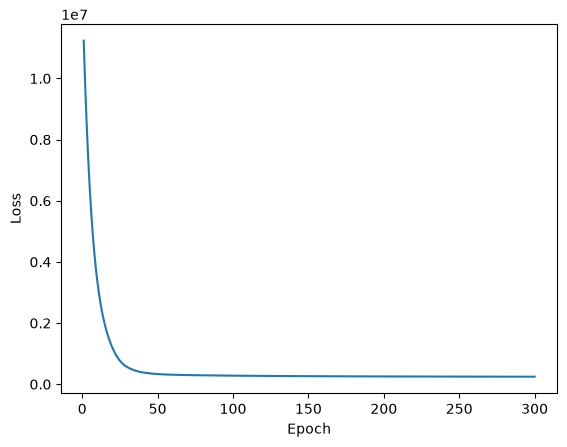

first loss: 11233914.0
last loss: 245936.4375
decrease in percent: 97.81076802350455


In [33]:
# @title c6.2 [0pt]
# YOUR CODE HERE
import matplotlib.pyplot as plt

#removed the extra plot styling, keep the basic graph for now
#plt.figure(figsize=(8, 4))
#plt.grid(alpha=0.3)
#plt.tight_layout()
plt.plot(range(1, len(losses)+1), losses)
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.show()

print("first loss:", losses[0])
print("last loss:", losses[-1])
decrease = 100 * (1 - losses[-1] / losses[0])
print("decrease in percent:", decrease)
#TODO: tidy the extra prints before handing in, but keep the graph and the 300 epoch outputs

The loss drops a lot at the beginning, then goes down more slowly. It starts at about 11233914 and ends at about 245936, a decrease of about 97.81%. This seems reasonable as the model has less left to improve after the first few rounds. It does not mean that all the word comparisons will be right, so those still need checking below.

#TODO: review this note together with the graph before handing in.

<font color="red">**Don't clear the output of the above cell!**</font>

### Validation (Similarity)

Curious to see what this network has learned? Let's perform a simple validation experiment.

We will check which words the model considers the most similar to other words. To that end, we need a notion of __similarity__. One of the most common measures of similarity in high-dimensional vector spaces is the cosine similarity.

The cosine similarity of two vectors $\vec{a}, \vec{b}$ is given as:
$$sim(\vec{a}, \vec{b}) = \frac{\vec{a}\cdot \vec{b}}{|\vec{a}|_2 \cdot |\vec{b}|_2}$$

where $|\vec{x}|_2$ is the $L_2$-norm of the $\vec{x}$.

The function `similarity` below accepts two words, a vocabulary and the network's output vectors, and computes the similarity between these two words. For an outside-vocabulary word similarity is 0.

In [34]:
def similarity(word_i: str, word_j: str, vocab: Dict[str, int], vectors: FloatTensor) -> float:
    if not(word_i in vocab and word_i in vocab): return 0.
    i, j = vocab[word_i], vocab[word_j]
    v_i = vectors[i] / torch.linalg.vector_norm(vectors[i])  # a/|a|
    v_j = vectors[j] / torch.linalg.vector_norm(vectors[j])  # b/|b|
    sim = torch.dot(v_i, v_j)
    return sim

Let's check out some examples. Consider the word pairs below and, optionally, add your own word pairs if it helps to support your answer:

In [35]:
word_vectors = network.get_vectors().detach()

for pair in [
    ("cruciatus", "imperius"),
    ("avada", "kedavra"),
    ("hogwarts", "school"),
    ("goblin", "hagrid"),
    ("giant", "hagrid"),
]:
    print(f"Similarity between '{pair[0]}' and '{pair[1]}' is: {similarity(pair[0], pair[1], vocab, word_vectors)}")

Similarity between 'cruciatus' and 'imperius' is: 0.49876099824905396
Similarity between 'avada' and 'kedavra' is: 0.6552070379257202
Similarity between 'hogwarts' and 'school' is: 0.7654939293861389
Similarity between 'goblin' and 'hagrid' is: 0.27460339665412903
Similarity between 'giant' and 'hagrid' is: 0.5027310848236084


#### i3 [1pt]
Give an interpretation of the results. Do the scores correspond well to your perceived similarity of these word pairs?

**ANSWER**: <font color="red">Most of these results make sense to me. Hogwarts and school have the highest score, about 0.765, which fits because Hogwarts is a school. Avada and kedavra score about 0.655. They belong to the same spell, although they are not words with the same meaning. Cruciatus and imperius score about 0.499. They are both curses but do different things, so some similarity seems reasonable.

Giant and Hagrid score about 0.503, compared with only 0.275 for goblin and Hagrid. This also fits, since Hagrid is half-giant and not a goblin. The smaller goblin score may come from them appearing in some similar magical-world contexts.

The scores show similarities in how words are used. They are not probabilities, and 0.765 does not mean that two words are 76.5 percent identical. The results look useful, but there is only a small corpus and 30 numbers for each word.</font>

To obtain the similarities of one word against all other words in the corpus, use torch functions and follow the equation ($\vec{c}_i$ is $i$th row of $\mathbf{C}$):
$$sim(\vec{w}, \mathbf{C}) = \frac{\vec{w}\cdot \mathbf{C}}{|\vec{w}|_2 \cdot |\mathbf{C}|_2} = \Big(\frac{\vec{w}\cdot \vec{c}_1}{|\vec{w}|_2 \cdot |\vec{c}_1|_2},\ldots,\frac{\vec{w}\cdot \vec{c}_N}{|\vec{w}|_2 \cdot |\vec{c}_N|_2}\Big)$$

Using `similarity` as a reference, write `similarities`, which accepts one word, a vocabulary and the network's output vectors and computes the similarity between the word and the entire corpus. **If a word is out of vocabulary, it should return a matrix of 0 similarities.**

_Hint_: $\mathbf{C} \in \mathbb{R}^{N, D}$, $\vec{w} \in \mathbb{R}^{1, D}$, $sim(\vec{w}, \mathbf{C}) \in \mathbb{R}^{1, N}$

In [36]:
# @title c7 [4pt]
def similarities(word_i: str, vocab: Dict[str, int], vectors: FloatTensor) -> FloatTensor:
    # use torch functions. Don't iterate over rows of vectors matrix!
    if word_i not in vocab:
        zeros = vectors.new_zeros((1, len(vocab)))
        return zeros

    #normalise all the rows first. eps avoids dividing by zero.
    unit_vectors = torch.nn.functional.normalize(vectors, p=2, dim=1, eps=1e-12)
    i = vocab[word_i]
    word_vector = unit_vectors[i]
    word_vector = word_vector.unsqueeze(0) #need a row, not a flat vector
    #the dot product is cosine similarity after normalising the vectors
    sims = word_vector @ unit_vectors.T
    #print(sims.shape) #should be (1, number of words)
    return sims

In [37]:
# TEST c7a
assert similarities('harry', vocab, word_vectors).shape == torch.Size([1, len(vocab)])
assert similarities('cow', vocab, word_vectors).shape == torch.Size([1, len(vocab)])

Now we can manipulate the word vectors to find out what the corpus-wide most similar words to a query word are!

In [38]:
def most_similar(word_i: str, vocab: Dict[str, int], vectors: FloatTensor, k: int) -> List[str]:
    """ Returns a list of k words that are most similar to word_i
        The list excludes word_i itself
    """
    sims = similarities(word_i, vocab, vectors)
    _, topi = sims.topk(dim=-1, k=k+1)
    topi = topi.view(-1).cpu().numpy().tolist()
    inv = {v: i for i, v in vocab.items()}
    return [inv[i] for i in topi if inv[i] != word_i][:k]

In [39]:
# TEST c7b
for word in [
    "forbidden", "myrtle", "gryffindor", "wand", "quidditch", "marauder",
    "horcrux", "phoenix", "triwizard", "screaming", "letter"
]:
    print(f"Most similar words to '{word}': {most_similar(word, vocab, word_vectors, 6)}")

Most similar words to 'forbidden': ['shadows', 'grounds', 'forest', 'lawns', 'mountains', 'ahead']
Most similar words to 'myrtle': ['moaning', 'bathroom', 'hid', 'toilet', 'sobbing', 'properly']
Most similar words to 'gryffindor': ['ravenclaw', 'team', 'wood', 'possession', 'quidditch', 'beat']
Most similar words to 'wand': ['spoke', 'face', 'shot', 'onto', 'struggled', 'flew']
Most similar words to 'quidditch': ['winning', 'saturday', 'team', 'training', 'captain', 'seeker']
Most similar words to 'marauder': ['lucky', 'gotten', 'convinced', 'map', 'locked', 'set']
Most similar words to 'horcrux': ['sword', 'object', 'goblin', 'destroy', 'horcruxes', 'safe']
Most similar words to 'phoenix': ['feather', 'fawkes', 'spinning', 'building', 'connected', 'murder']
Most similar words to 'triwizard': ['tournament', 'champions', 'cedric', 'cup', 'champion', 'quidditch']
Most similar words to 'screaming': ['frozen', 'scream', 'voices', 'screams', 'cold', 'forced']
Most similar words to 'letter':

#### i4 [3pt]

Interpret the results in the context of Harry Potter books.
- Do these most similar words make sense (are they actually similar to the query words)?
- Are there any patterns you can see in the "errors" (the words that you wouldn't consider actually similar to the query word in general, in everyday life)?
- Which examples are instances of similarity (if any) and relatedness (if any)?
- Any other observations are welcome.

Illustrate your answers with examples from your model's output.

**ANSWER**: <font color="red">Some of the word lists look quite sensible. Myrtle has moaning, bathroom, toilet and sobbing. Triwizard has tournament, champions, cedric and cup. Quidditch has team, training, captain and seeker. These words are connected in the books, but usually cannot replace each other in a sentence.

For actual similarity, Gryffindor and Ravenclaw are both houses. Letter and letters have almost the same meaning, just a different number. Screaming also finds scream and screams. For relatedness, letter finds Hedwig, Errol and ink. These are connected with letters rather than being other words for a letter. The same goes for phoenix with feather and Fawkes.

Not all of the expected words come first. Forest is third for forbidden, after shadows and grounds. Map is fourth for marauder. Horcrux gives sword, destroy and horcruxes, so it seems to pick up the story about destroying them as well as the objects themselves.

Wand is less convincing. Its list is spoke, face, shot, onto, struggled and flew. These look like words from action scenes, not similar objects. Phoenix also has spinning, building and murder, which are harder to explain. My guess is that repeated scenes and the small amount of text make some words look more similar than they really are. The 30-dimensional vectors also have limited room to represent everything. That is a possible explanation, not something these lists prove. Overall, the model often finds words that are connected in the story, even when their everyday meanings are quite different.</font>

Overall it's quite impressive; we managed to encode a meaningful portion of the corpus statistics in only $30$ numbers per word!
(A compression ratio of >99%)

<div class="alert alert-block alert-info">
<b>Note:</b> The word vectors obtained by this process are (to a small extent) random, due to the random initialization of the embedding layers. If you are unhappy with your results, you can repeat the experiment a few times or try to toy around with the hyper-parameters (the smoothing factor of ${X}$, $x_{max}$, $\alpha$, the number of epochs and the dimensionality of the vector space). But do this as your own experiments outside the submission file.
</div>

Word vectors, however, contain way more information than just word co-occurrence statistics. Hold tight until the next assignment, where we will see how word vectors may be used to infer information spanning entire phrases and sentences.

### Validation (Word Analogies)

From the paper:
> The word analogy task consists of questions like "$a$ is to $b$ as $c$ is to __?" To correctly answer this question, we must find the word $d$ such that $w_d \approx w_b - w_a + w_c$ according to the cosine similarity.

Write your own function that performs the word analogy task.  

In addition to the standard approximation $w_d \approx w_b - w_a + w_c$, implement another non-standard but intuitive approximation where we are searching $w_d$ that maximizes the following similarity $w_a - w_b \approx w_c - w_d$.  

Let's see which criteria will give the best results, or maybe both give the same results.    

_Hint_: Take a look at the code a few cells back. Most of what you need is already there.

In [40]:
# @title c8 [5pt]
def analogy(
    word_a: str, word_b: str, word_c: str, vocab: Dict[str, int],
    vectors: FloatTensor, k: int=5, standard: bool=True
) -> List[str]:
    """ Return a list of k words whose vectors are most similar to the solution vector of the analogy.
        The first element means the most similar, followed by the rest in decreasing similarity.
        word_a, word_b, and word_c are never returned as a part of the list.
        param standard=True uses the standard approximation equation, =False uses the alternative one.
        Missing input words return []; k is capped at the number of eligible words.
    """
    if k <= 0:
        return []
    if word_a not in vocab or word_b not in vocab or word_c not in vocab:
        return []

    #write out the three lookups separately now
    #a, b, c = (vocab[word] for word in (word_a, word_b, word_c))
    a = vocab[word_a]
    b = vocab[word_b]
    c = vocab[word_c]

    if standard:
        target = vectors[b] - vectors[a] + vectors[c]
        candidates = vectors
    else:
        target = vectors[a] - vectors[b]
        candidates = vectors[c].unsqueeze(0) - vectors
        #compare a-b with c-d, not with d itself

    #normalise the difference vectors too when using the alternative method
    scores = torch.nn.functional.cosine_similarity(
        candidates, target.unsqueeze(0), dim=1, eps=1e-12
    )
    excluded = sorted({a, b, c}) #one word could appear more than once in the question
    scores[excluded] = -torch.inf #don't return the question words
    number_to_return = min(k, len(vocab) - len(excluded))
    indices = scores.topk(number_to_return).indices.cpu().tolist()

    #these loops just look up names, the vector calculations above still use torch
    inverse_vocab = {}
    for word, index in vocab.items():
        inverse_vocab[index] = word

    answer = []
    for index in indices:
        answer.append(inverse_vocab[index])
    return answer

Some example triplets to test your analogies on:

In [41]:
# TEST c8
triplets = [("padma", "parvati", "fred"),
            ("avada", "kedavra", "expecto"),
            ("dungeon", "slytherin", "tower"),
            ("scabbers", "ron", "hedwig"),
            ("ron", "molly", "draco"),
            ("durmstrang", "viktor", "beauxbatons"),
            ("snape", "potions", "trelawney"),
            ("harry", "seeker", "ron"),
            # ---------------------
            # YOUR CODE HERE (3 examples)
            ("harry", "potter", "draco"), #expected: malfoy
            ("ron", "weasley", "hermione"), #expected: granger
            ("gryffindor", "sword", "slytherin") #expected: locket
           ]

print("Mode: d ~ c - a + b")
for a, b, c in triplets:
    print("{:^16} is to {:^16} as {:^16} is to\t{}".format(a, b, c, analogy(a, b, c, vocab, word_vectors, 5, standard=True)))

print("\nMode: a - b ~ c - d")
for a, b, c in triplets:
    print("{:^16} is to {:^16} as {:^16} is to\t{}".format(a, b, c, analogy(a, b, c, vocab, word_vectors, 5, standard=False)))

Mode: d ~ c - a + b
     padma       is to     parvati      as       fred       is to	['pretending', 'george', 'mrs', 'told', 'ron']
     avada       is to     kedavra      as     expecto      is to	['patronum', 'slowed', 'dementor', 'hood', 'steam']
    dungeon      is to    slytherin     as      tower       is to	['gryffindor', 'training', 'points', 'hundred', 'ravenclaw']
    scabbers     is to       ron        as      hedwig      is to	['carrying', 'awake', 'parcel', 'time', 'five']
      ron        is to      molly       as      draco       is to	['coolly', 'narcissa', 'unaware', 'forgive', 'pleasantly']
   durmstrang    is to      viktor      as   beauxbatons    is to	['delacour', 'maxime', 'cedric', 'judges', 'support']
     snape       is to     potions      as    trelawney     is to	['herbology', 'divination', 'exams', 'exam', 'binns']
     harry       is to      seeker      as       ron        is to	['score', 'chasers', 'hufflepuff', 'flint', 'spectacular']
     harry       i

Some minimal emergent intelligence :) *(hopefully..)*. 🧙‍♀️

#### i5 [2pt]

Which analogy equation did give the best results for the provided analogy samples?  

Come up with three additional analogies in the context of Harry Potter.
Add them to the list of analogies in the code above and run the analogy computation.

Interpret the results of the best performing analogy equation (if any):
- For which analogies did the model manage to guess the correct answers (taking the first word in the output to be the model's "guess")?
- For which analogies are the correct answers present in the top K words?
- Do you see any patterns in the cases when the model didn't solve the task correctly? In other words, when the model's guess was wrong, can you suggest why the model guessed what it guessed?

**ANSWER**: <font color="red">The standard equation works better in this run. For the eight examples from the assignment, it gets 2 expected words first and 5 somewhere in the first five results. The other equation gets 0 first and 2 in the first five. Here I am counting exact words, which matters for Fleur below.

The standard method gets patronum first for avada/kedavra/expecto, and gryffindor first for dungeon/slytherin/tower. I use Gryffindor as the intended answer, although Ravenclaw also has a tower and appears fifth. George is second for padma/parvati/fred, after pretending. Narcissa is second for ron/molly/draco, after coolly. Divination is second for snape/potions/trelawney, after herbology. So those three have the right answer in the list but not at the top.

Harry is missing from the first five for scabbers/ron/hedwig. The list starts with carrying, awake and parcel. Keeper is also missing for harry/seeker/ron. Instead it gives score, chasers and hufflepuff, which are connected to Quidditch but do not answer the question.

There is an interesting naming issue with durmstrang/viktor/beauxbatons. Both methods give delacour first rather than fleur. That is the intended person, just her surname. If I accept that, the standard method gets 3/8 first and 6/8 in the first five, while the other method gets 1/8 first and 3/8 in the first five.

The three added examples are harry/potter/draco, expecting malfoy; ron/weasley/hermione, expecting granger; and gryffindor/sword/slytherin, expecting locket. The first two ask for surnames, and the last asks for an object associated with the founder or house. Neither method finds these expected words in the first five. The standard method starts with sneered, leave and goblin. Sneered and coolly could come from descriptions of Draco. Goblin, griphook, horcrux and object seem connected to the sword storyline, but are not the locket.

It seems easier for the model to find a shared topic than to follow every relationship, such as a pet and its owner or a first name and surname. The small corpus and limited vectors may contribute to that. Also, although the two equations can be rearranged algebraically, their cosine comparisons use different vectors: word vectors in one case and differences between vectors in the other. This helps explain why their rankings differ. These few examples do not show that one method will always be better.</font>

# <font color="red">Challenge-based Assignment</font>

## Counting co-occurrences

In the beginning of the notebook you were provided with a pickle of co-occurrence counts. But how were these counts obtained?  
You will find this out when you complete this exercise.  

First, we obtain the plain text corpus of the Harry Potter book series and place the book files in the current directory.

In [ ]:
!git clone https://github.com/ErikaJacobs/Harry-Potter-Text-Mining.git

In [ ]:
!cp Harry-Potter-Text-Mining/Book\ Text/* .

In research, it is relatively common that papers don't include all necessary details for replicating the experiments. This is often due to the lack of space in the paper, overlooking certain details, or simply a bad practice.

We will give you several hints on how the co-occurrence matrix was obtained. With the hints and the provided data in the pickle file, you should be able to replicate the exact content of the co-occurrence matrix from the pickle. Here are the hints:

1.   Tokenization of the data was done in a shallow but effective way: replace all punctuations with white space and delimit tokens on white space;
2.   `nltk` and `string` libraries where used for identifying punctuations and stopwords;
3.   Context windows are symmetric and don't span across chapters (i.e., the last word of chapter $N$ is not co-occuring with the first word of chapter $N+1$).
4.   The vocabulary was obtained based on the frequency cutoff.

How the context words were counted is something you need to find out.  
Remember that the provided pickle file includes a lot of information, so please utilize it wisely.

To replicate the co-occurrence counts, complete the function below. Then use it to find out the exact values of `cutoff` and `window_size` that result in the co-occurrence counts identical to the provided ones. No need to provide the code for finding the exact values. Just use them in the next TEST code cell.

Feel free to import any standard python library. Use the same cell code for importing libraries and defining auxiliary functions (if any).
The code will be evaluated not only on the correctness of the output but also on efficiency. It should be able to extract the counts and create the tensor in less than a minute (in the colab environment).

In [ ]:
# @title c9 [8pt]
import csv, string, nltk
nltk.download('stopwords')

def read_book_files(files: List[str], cutoff: int=10, window_size: int=20,
                    verbose: bool=False):
    """ Input:
            file - a list of file paths;
            cutoff - vocab excludes words with occurrence counts < cutoff;
            window_size - size of the left and right windows (individually);
            verbose - when set to False prints nothing
        Outputs a tuple of:
            voc - mapping of vocabulary to indices;
            dd_cnt - dict of dict of co-occurrence counts based on the voc; (not a defaultdict)
            X - Tensor with |vocab|x|vocab| size and co-occurrence counts. This should be based on dd_cnt
    """

    NotImplemented

    return voc, dd_cnt, X

In [ ]:
en_stop = set(nltk.corpus.stopwords.words('english'))
en_stop

In [ ]:
# TEST
# Fill in the found cutoff and window_size values
# Cell execution shouldn't take more than 60sec
%%time
my_vocab, my_contexts, my_X = \
    read_book_files([ f"HPBook{n}.txt" for n in range(1,8) ],
                    cutoff=10, window_size=10) # just dummy 10 as args

In [ ]:
#

In [ ]:
# TEST c9
# This makes sure the value types are as expected
assert my_vocab['1'] == 0
assert isinstance(my_vocab, dict)
assert isinstance(my_contexts, dict)
assert 'potter' in my_contexts['harry']
assert isinstance(my_X, torch.Tensor)

<font color="red">**Don't clear the output of the above cell!**</font>

#### i6 [1pt]

What are the values of `cutoff` and `window_size` that replicates the provided counts?

**Describe** <font color="red">with 50-100 words</font> the process of finding the correct underlying algorithm of `read_book_files` and how the correct values of `cutoff` and `window_size` were found.

Assume that we have access only to the contents of the pickle file and the Harry Potter text corpus.
Devise an optimal strategy for determining the values of `cutoff` and `window_size` that only counts tokens in the corpus.
**Describe** the strategy and illustrate it with actual tokens and their counts from the pickle file and the corpus.

**ANSWER**: <font color="red">YOUR BOTH ANSWER HERE IN RED (250-400 words)</font>

# <font color="red">Work description</font>

~~Describe your approach to solving the exercises, for example, what steps you took first, followed by subsequent actions, which parts you found most challenging or easy, any specific helpful assistance received from TAs, whether you used GenAI, to what extent, at what stage, which one, how helpful was it, etc.~~

<font color="red">YOUR ANSWER HERE</font>   [100-200 words]

#TODO: incorporate this development note into the final 100-200 word work description after stage 6 is finished.
Development note for stages 3-5: OpenAI Codex was used to implement the model, training and validation code, run numerical and execution checks, and draft i3-i5 from the recorded outputs. The run used 30 dimensions, Adam, seed 0, learning rate 0.05 and 300 epochs.
#TODO: review the generated explanations and update the contribution information before submission.


# Acknowledgment

The jupyter notebook was initially created by Konstantinos Kogkalidis and Tejaswini Deoskar.  
Recent changes, including adaptation to the Colab environment and the exercise on reconstructing a co-occurrence matrix, are by Lasha Abzianidze.